In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("hillstorm_no_indices.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (64000, 12)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [2]:
print("Missing values:")
display(df.isnull().sum())

print("Exact duplicate rows:", df.duplicated().sum())

print("Unique marketing groups:")
display(df["segment"].value_counts())

Missing values:


,0
recency,0
history_segment,0
history,0
mens,0
womens,0
zip_code,0
newbie,0
channel,0
segment,0
visit,0


Exact duplicate rows: 6562
Unique marketing groups:


,count
segment,
Womens E-Mail,21387
Mens E-Mail,21307
No E-Mail,21306


In [3]:
duplicate_rows = df[df.duplicated(keep=False)]

print("Rows involved in exact duplicates:",
      len(duplicate_rows))

display(duplicate_rows.head(10))

Rows involved in exact duplicates: 7634


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
16,5,1) $0 - $100,29.99,1,0,Surburban,0,Phone,Mens E-Mail,0,0,0.0
20,9,1) $0 - $100,29.99,0,1,Surburban,1,Phone,No E-Mail,0,0,0.0
23,2,1) $0 - $100,29.99,0,1,Urban,1,Phone,No E-Mail,0,0,0.0
33,9,1) $0 - $100,29.99,1,0,Surburban,1,Phone,Mens E-Mail,0,0,0.0
34,3,1) $0 - $100,29.99,1,0,Rural,0,Web,Womens E-Mail,0,0,0.0
45,10,1) $0 - $100,29.99,1,0,Surburban,0,Phone,No E-Mail,0,0,0.0
52,7,1) $0 - $100,29.99,0,1,Urban,1,Phone,Mens E-Mail,0,0,0.0
79,2,1) $0 - $100,29.99,0,1,Surburban,0,Phone,Mens E-Mail,0,0,0.0
107,12,1) $0 - $100,29.99,0,1,Urban,1,Web,No E-Mail,0,0,0.0
114,4,1) $0 - $100,29.99,0,1,Urban,1,Web,Womens E-Mail,0,0,0.0


In [4]:
summary = df.groupby("segment").agg(
    customers=("conversion", "size"),
    visits=("visit", "sum"),
    conversions=("conversion", "sum"),
    total_spend=("spend", "sum")
)

summary["visit_rate"] = (
    summary["visits"] / summary["customers"] * 100
)

summary["conversion_rate"] = (
    summary["conversions"] / summary["customers"] * 100
)

display(summary.round(2))

,customers,visits,conversions,total_spend,visit_rate,conversion_rate
segment,,,,,,
Mens E-Mail,21307,3894,267,30311.69,18.28,1.25
No E-Mail,21306,2262,122,13908.33,10.62,0.57
Womens E-Mail,21387,3238,189,23038.11,15.14,0.88


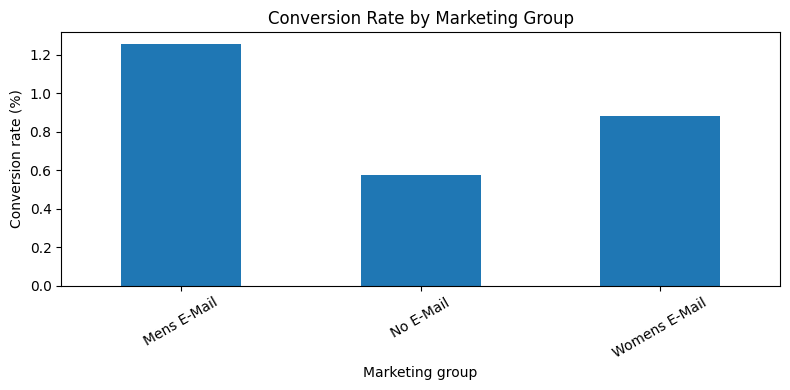

In [5]:
summary["conversion_rate"].plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Conversion Rate by Marketing Group")
plt.ylabel("Conversion rate (%)")
plt.xlabel("Marketing group")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [6]:
num_rows = df.shape[0]
num_cols = df.shape[1]
num_duplicates = df.duplicated().sum()

best_segment = summary['conversion_rate'].idxmax()
best_conv_rate = summary['conversion_rate'].max()

print(f"Dataset overview: The dataset contains {num_rows} rows and {num_cols} columns.")
print(f"Data quality: The dataset contains {num_duplicates} exact duplicate rows.")
print(f"Marketing group analysis: The {best_segment} group has the highest observed conversion rate at {best_conv_rate:.2f}%.")

Dataset overview: The dataset contains 64000 rows and 12 columns.
Data quality: The dataset contains 6562 exact duplicate rows.
Marketing group analysis: The Mens E-Mail group has the highest observed conversion rate at 1.25%.


## Conclusion

- **Dataset overview:** The dataset contains 64,000 rows and 12 columns.
- **Data quality:** The dataset contains 6,562 exact duplicate rows. These records require further investigation before deciding whether to remove them.
- **Marketing group analysis:** The Mens E-Mail group has the highest observed conversion rate at 1.25%.
- **Next steps:** Further investigate duplicate records and validate the dataset before proceeding with causal inference.

**Note:** Conversion-rate differences are descriptive and do not, by themselves, establish causal effects.